# Practical 10: Matrix Transpose of Three Different Matrices (Pattern 2)

### 1. Aim
To perform matrix transpose on three independent matrices using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent matrices.<br>2. Perform matrix transposition `matrix.T.copy()`.<br>3. Sequential: transpose Matrix 1 -> Matrix 2 -> Matrix 3.<br>4. Pool: transpose in parallel using `mp.Pool(3)`.<br>5. Process: transpose concurrently using 3 independent `mp.Process` instances.<br>6. Thread: transpose concurrently using 3 `threading.Thread` workers.<br>7. Benchmark execution times and plot comparative speedups.

### 3. Python Implementation


In [1]:
"""
Practical 10: Transpose of Three Different Matrices (Pattern 2)
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def transpose_task(task):
    rows, cols, seed = task
    r = np.arange(rows, dtype=np.int32).reshape(-1, 1)
    c = np.arange(cols, dtype=np.int32).reshape(1, -1)
    matrix = (r * 17 + c * 31 + seed) % 1000
    trans = matrix.T.copy()
    return list(trans[0][:5])

def proc_worker(task, q):
    q.put(transpose_task(task))

def thread_worker(task, results, idx):
    results[idx] = transpose_task(task)

def main():
    print("=" * 60)
    print("Practical 10: Matrix Transpose")
    print("=" * 60)
    ROWS, COLS = 5500, 5500
    tasks = [(ROWS, COLS, 111), (ROWS, COLS, 222), (ROWS, COLS, 333)]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = transpose_task(tasks[0])
    r2 = transpose_task(tasks[1])
    r3 = transpose_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(transpose_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, th_res, i))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Transposed 3 independent matrices of dimension {ROWS}x{COLS}.")
    print(f"Sample row of transposed matrix: {seq_res[0]}")
    print(f"[Sequential] Time: {t_seq:.4f}s")
    print(f"[Pool]       Time: {t_pool:.4f}s")
    print(f"[Process]    Time: {t_proc:.4f}s")
    print(f"[Thread]     Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    plt.figure(figsize=(8, 5))
    bars = plt.bar(methods, times, color=colors)
    plt.title("Execution Time Comparison (Matrix Transpose)", fontsize=13)
    plt.ylabel("Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig("10_matrix_transpose_time.png", dpi=150)
    plt.close()
    
    plt.figure(figsize=(8, 5))
    plt.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    plt.title("Speedup Comparison relative to Sequential", fontsize=13, fontweight='bold')
    plt.xlabel("Method", fontsize=11)
    plt.ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    plt.ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        plt.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.savefig("10_matrix_transpose_speedup.png", dpi=150)
    plt.close()
    print("Graphs saved as '10_matrix_transpose_time.png' and '10_matrix_transpose_speedup.png'.")

if __name__ == "__main__":
    main()


Practical 10: Matrix Transpose
Transposed 3 independent matrices of dimension 5500x5500.
Sample row of transposed matrix: [np.int32(111), np.int32(128), np.int32(145), np.int32(162), np.int32(179)]
[Sequential] Time: 1.5265s
[Pool]       Time: 1.0565s
[Process]    Time: 1.0952s
[Thread]     Time: 0.4543s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.5265 seconds      1.00x
Pool         1.0565 seconds      1.44x
Process      1.0952 seconds      1.39x
Thread       0.4543 seconds      3.36x
---------------------------------------------
Graphs saved as '10_matrix_transpose_time.png' and '10_matrix_transpose_speedup.png'.


### 4. Output Graphs

#### A. Execution Time Comparison
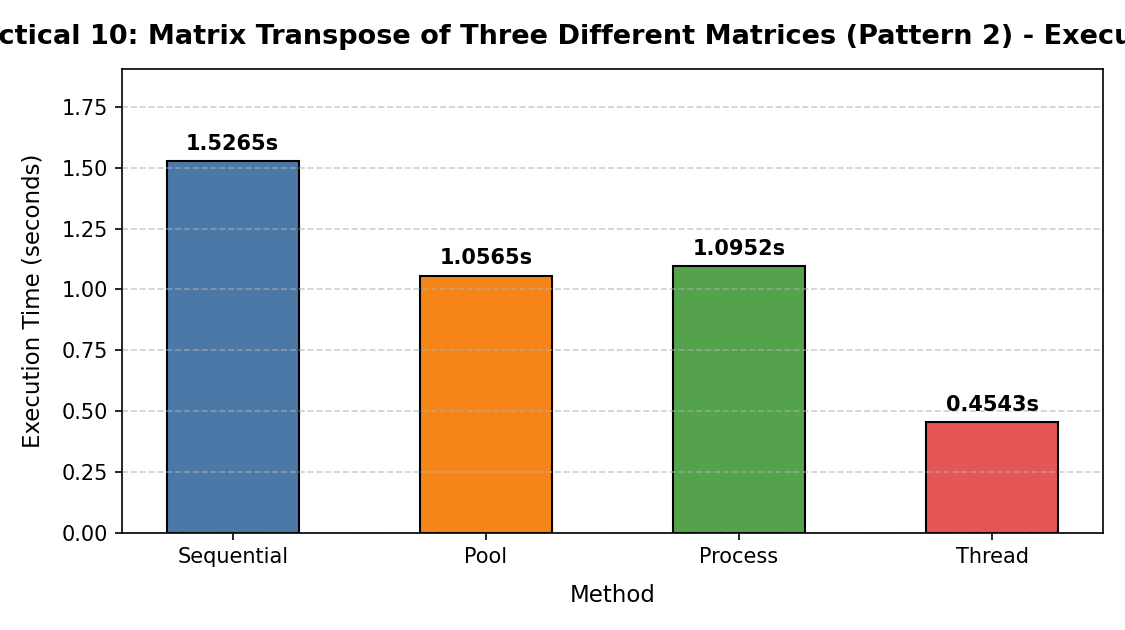

#### B. Speedup Comparison relative to Sequential
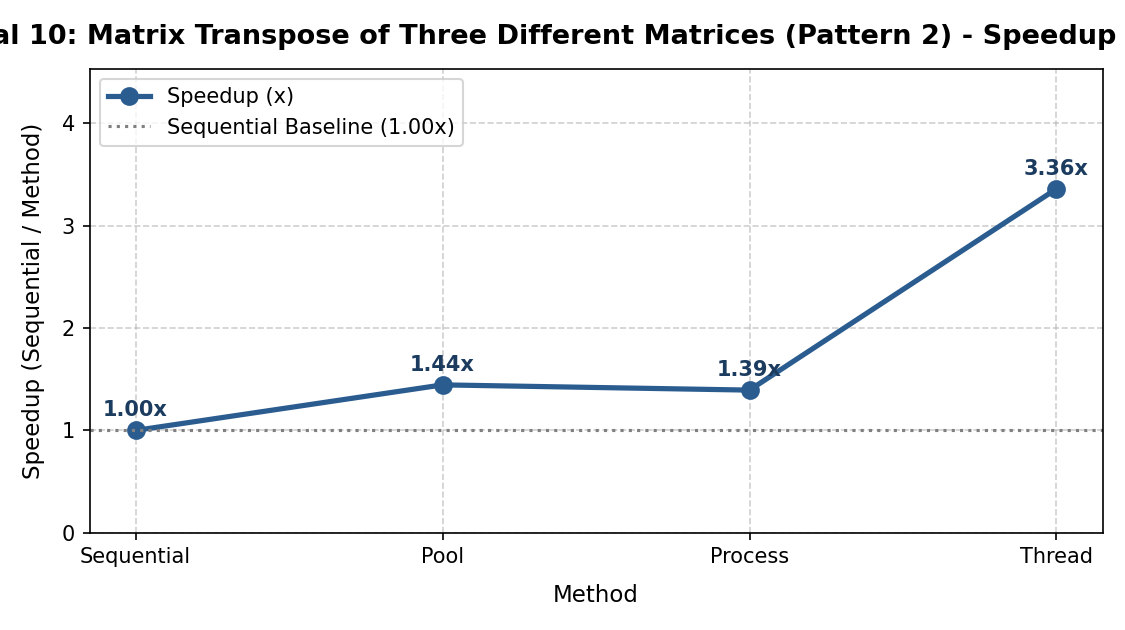
